<a href="https://colab.research.google.com/github/Deviapritha/Part-Assignments/blob/main/Python%20DA%20Assignment%202-Data%20Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import seaborn as sns

df = sns.load_dataset("taxis")


In [9]:
import seaborn as sns
import pandas as pd


df = sns.load_dataset("taxis")


print(df.isnull().sum())


print(df.isnull().sum()[df.isnull().sum() > 0])

numerical_cols = df.select_dtypes(include="number").columns
print("Numerical columns:", list(numerical_cols))

categorical_cols = df.select_dtypes(include=["object", "category"]).columns
print("Categorical columns:", list(categorical_cols))
for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())


for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()
        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value[0])
print("Missing values after cleaning:")
print(df.isnull().sum())


print("Final dataset shape:", df.shape)


print(df.head())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
Numerical columns: ['passengers', 'distance', 'fare', 'tip', 'tolls', 'total']
Categorical columns: ['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']
Missing values after cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Final dataset shape: (6433, 1

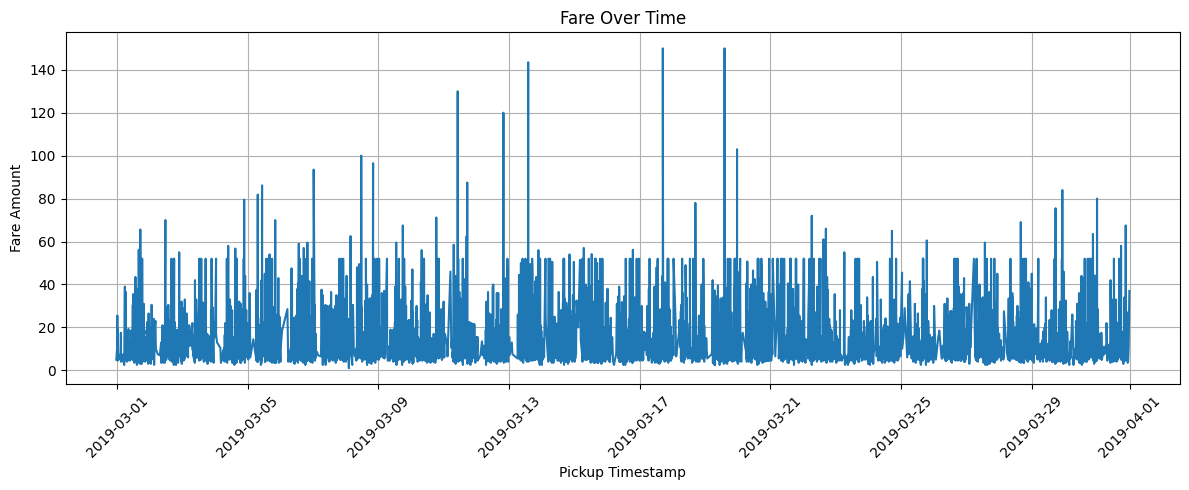

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df['pickup'] = pd.to_datetime(df['pickup'])
df = df.sort_values('pickup')

plt.figure(figsize=(12, 5))
plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

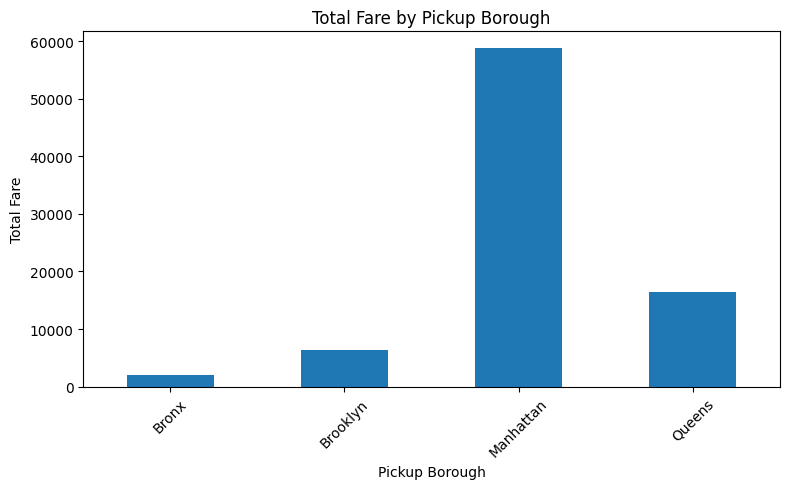

In [16]:
import matplotlib.pyplot as plt

borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8, 5))
borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

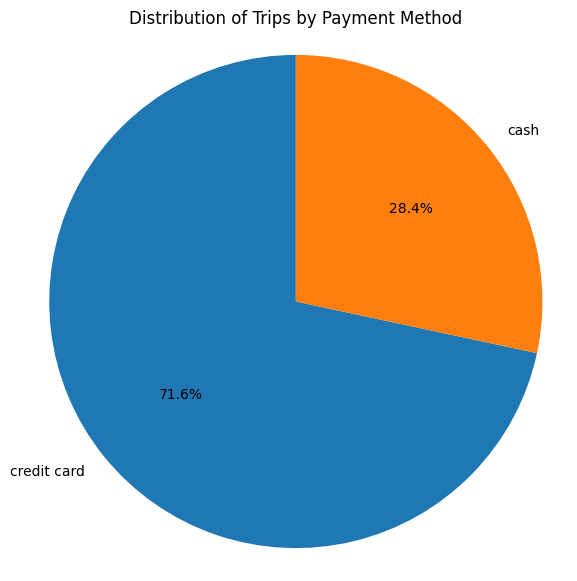

In [19]:
import matplotlib.pyplot as plt

payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.axis('equal')
plt.show()

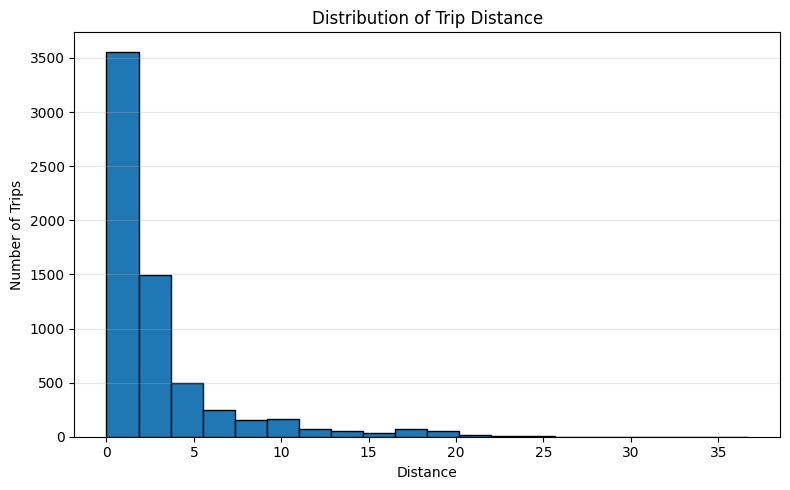

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df['distance'].dropna(), bins=20, edgecolor='black')

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

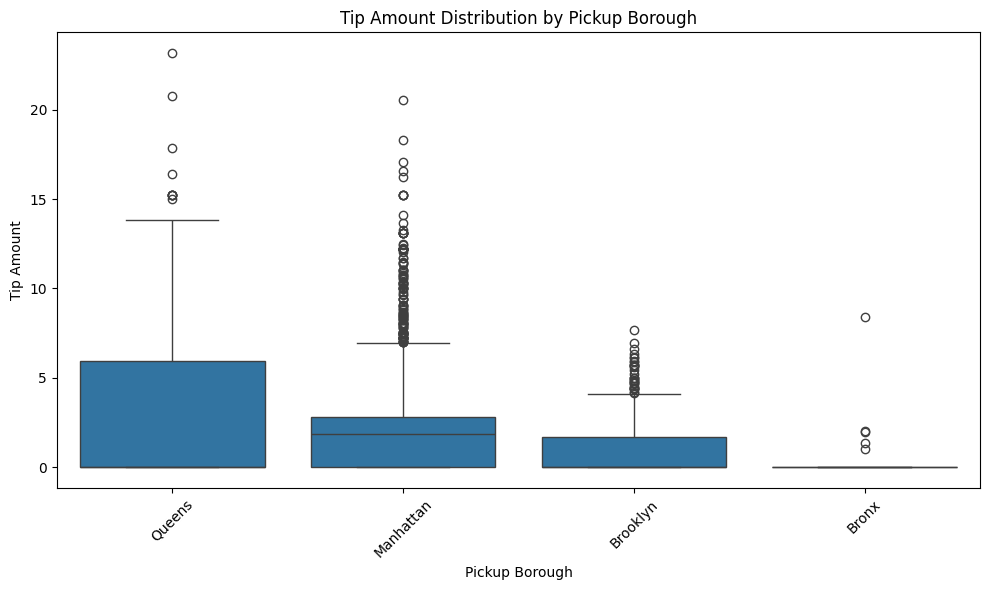

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip'
)

plt.title('Tip Amount Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

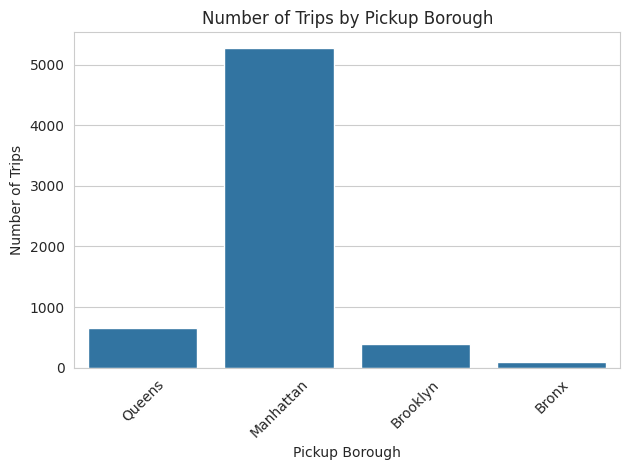

In [23]:
sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

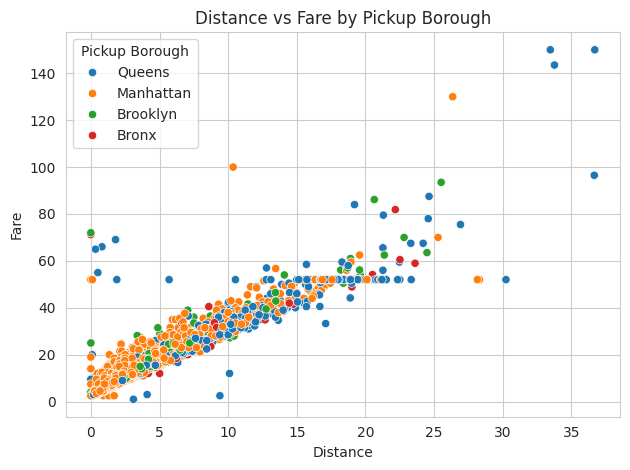

In [24]:
sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.legend(title='Pickup Borough')
plt.tight_layout()
plt.show()

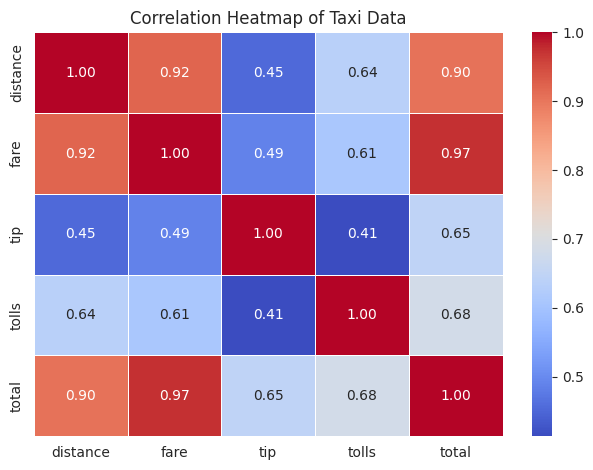

In [25]:
numerical_columns = ['distance', 'fare', 'tip', 'tolls', 'total']

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Taxi Data')
plt.tight_layout()
plt.show()

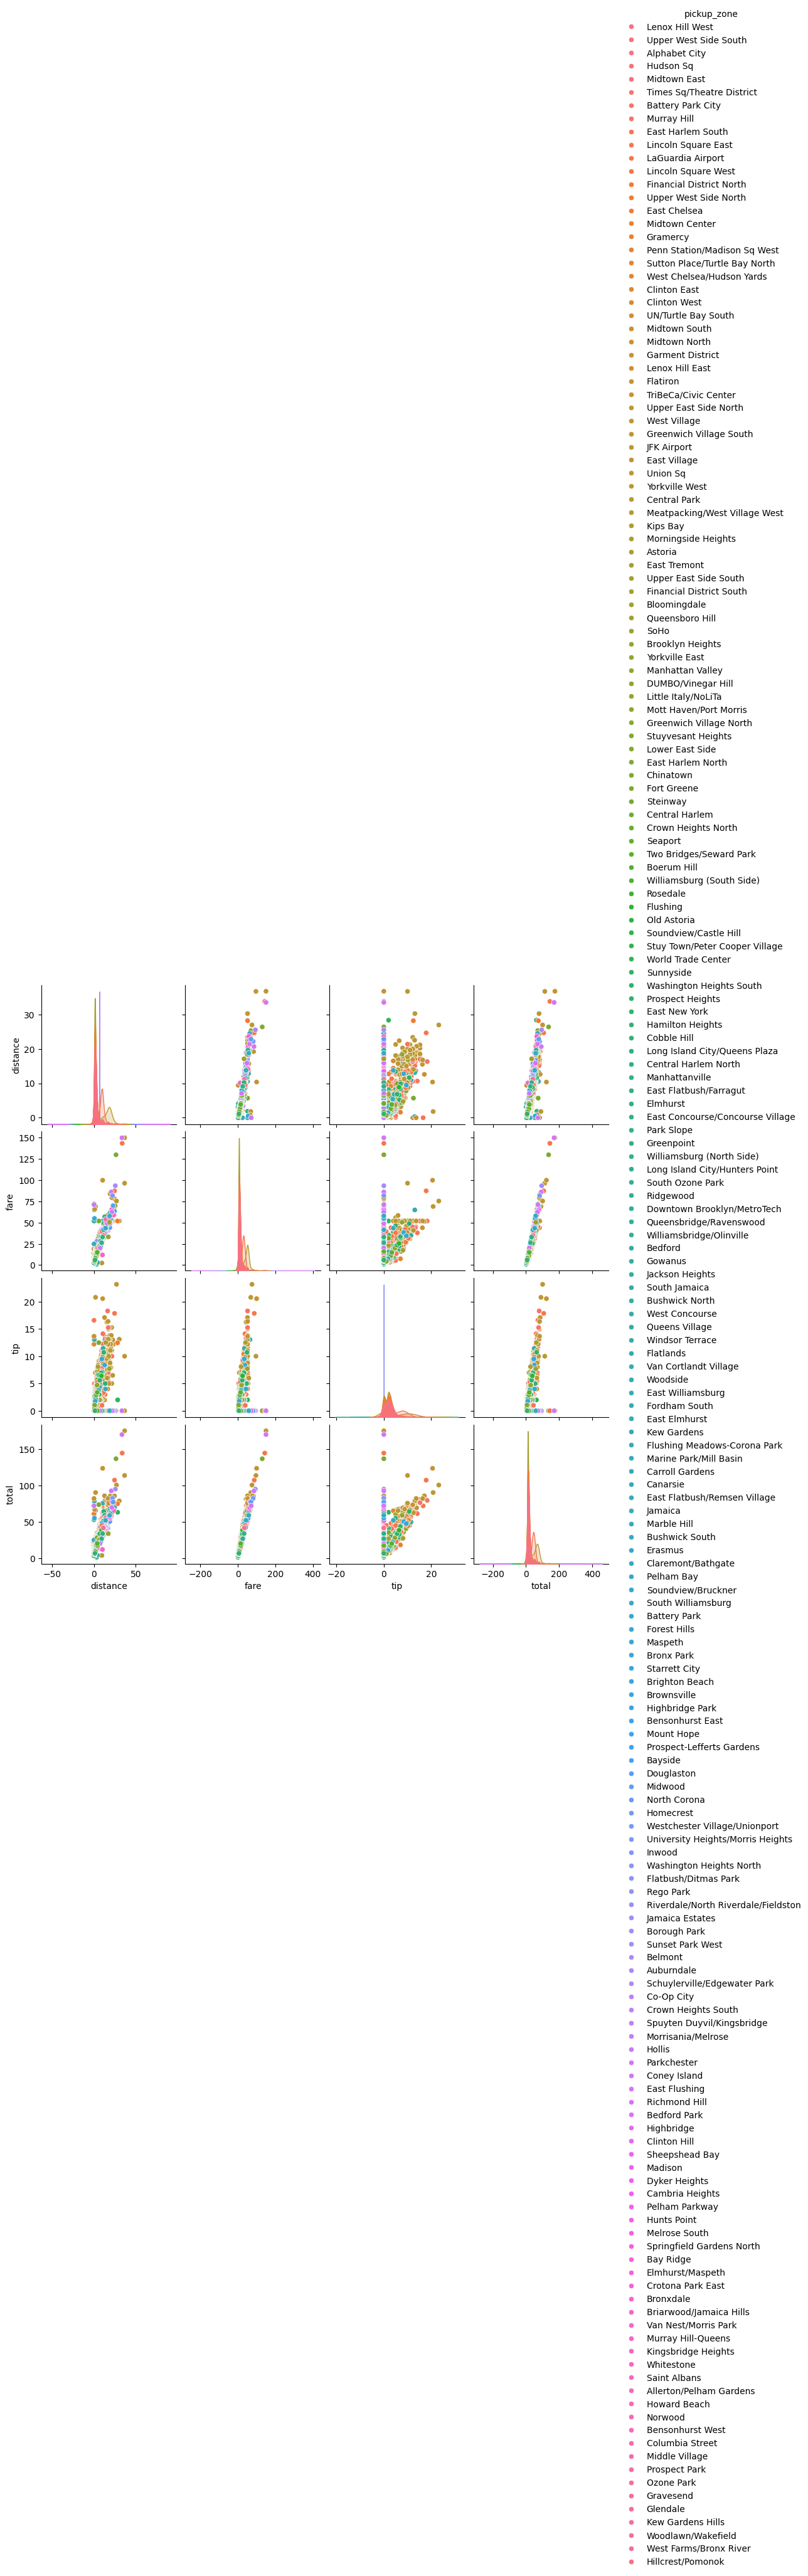

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

pairplot_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

sns.pairplot(
    pairplot_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()


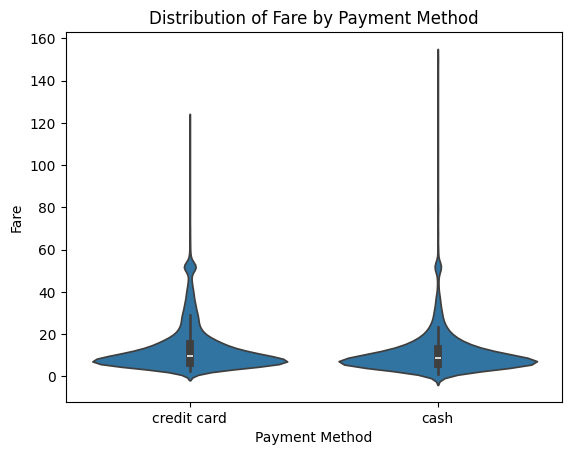

In [10]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

violin_data = df[['payment', 'fare']].dropna()

sns.violinplot(
    data=violin_data,
    x='payment',
    y='fare'
)

plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.show()
